In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 9)


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

First 5 Records:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [6]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [7]:
# Numerical columns
numerical_columns = ["Age", "Quantity", "Price per Unit", "Total Amount"]

# Descriptive statistics
statistics = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": df[numerical_columns].mode().iloc[0],
    "Standard Deviation": df[numerical_columns].std()
})

statistics

,Mean,Median,Mode,Standard Deviation
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


In [8]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

print("Date converted successfully!")
print(df["Date"].dtype)

Date converted successfully!
datetime64[us]


In [9]:
# Create Month column
df["Month"] = df["Date"].dt.to_period("M")

# Calculate monthly sales
monthly_sales = df.groupby("Month")["Total Amount"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


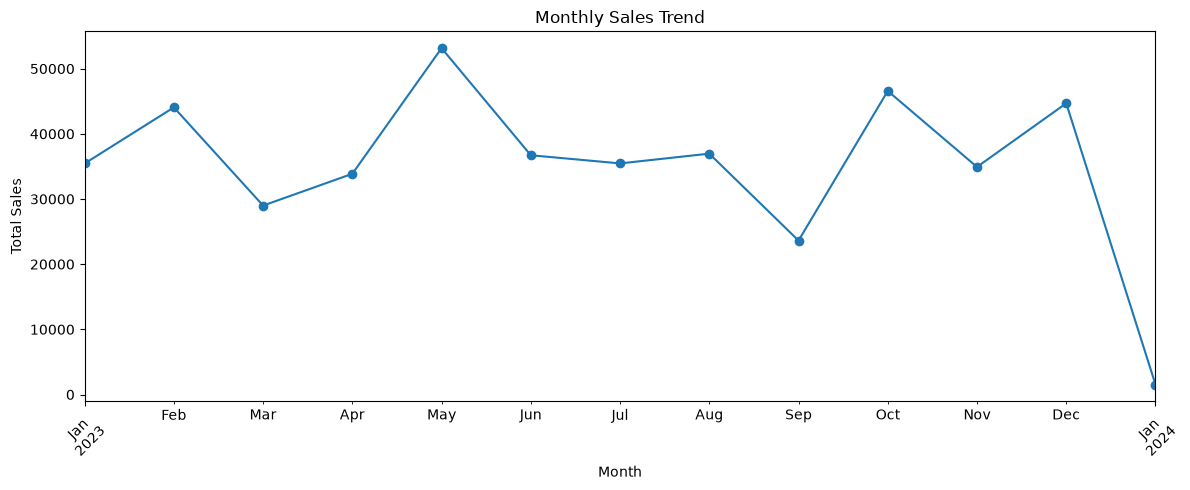

In [12]:
# Monthly Sales Trend

plt.figure(figsize=(12, 5))

monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

* May 2023 recorded the highest monthly sales of ₹53,150.
* September 2023 recorded the lowest sales during the full months of 2023, at ₹23,620.
* Sales increased again in October and December 2023.
* January 2024 shows very low sales because the dataset contains only a small number of transactions for that month.


In [13]:
# Create Quarter column
df["Quarter"] = df["Date"].dt.to_period("Q")

# Calculate quarterly sales
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

print("Quarterly Sales:")
print(quarterly_sales)

Quarterly Sales:
Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


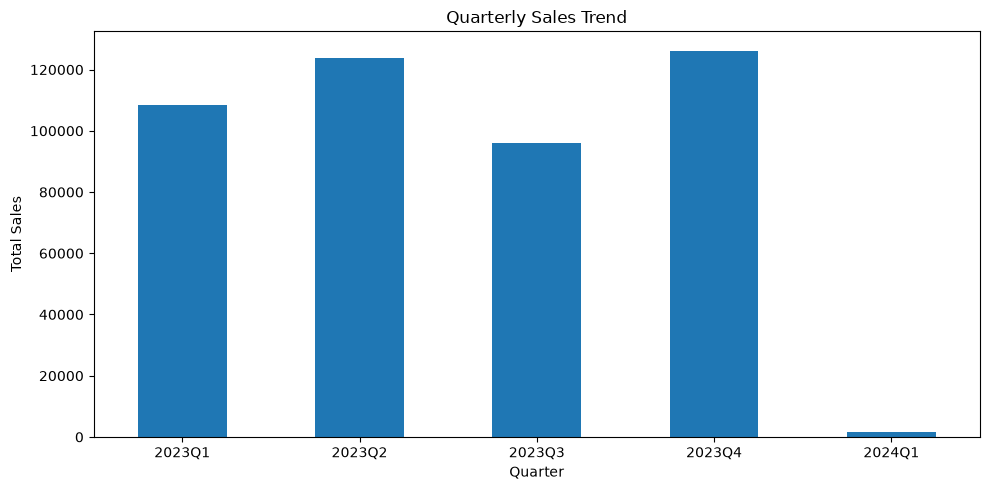

In [14]:
# Quarterly Sales Trend

plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind="bar")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

* The highest quarterly sales were recorded in Q4 2023, with total sales of ₹1,26,190.
* Q2 2023 showed higher sales than Q1 2023.
* Q3 2023 recorded the lowest quarterly sales among the complete quarters of 2023, with ₹96,045.
* Q1 2024 shows very low sales because the dataset contains only January 2024 transactions.


In [15]:
# Create Age Groups

bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

print("Age Groups created successfully!")
print(df[["Age", "Age Group"]].head(10))

Age Groups created successfully!
   Age Age Group
0   34     26-35
1   26     26-35
2   50     46-55
3   37     36-45
4   30     26-35
5   45     36-45
6   46     46-55
7   30     26-35
8   63     56-65
9   52     46-55


In [16]:
# Calculate sales by age group

age_group_sales = df.groupby("Age Group", observed=False)["Total Amount"].sum()

print("Sales by Age Group:")
print(age_group_sales)

Sales by Age Group:
Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-65     80410
Name: Total Amount, dtype: int64


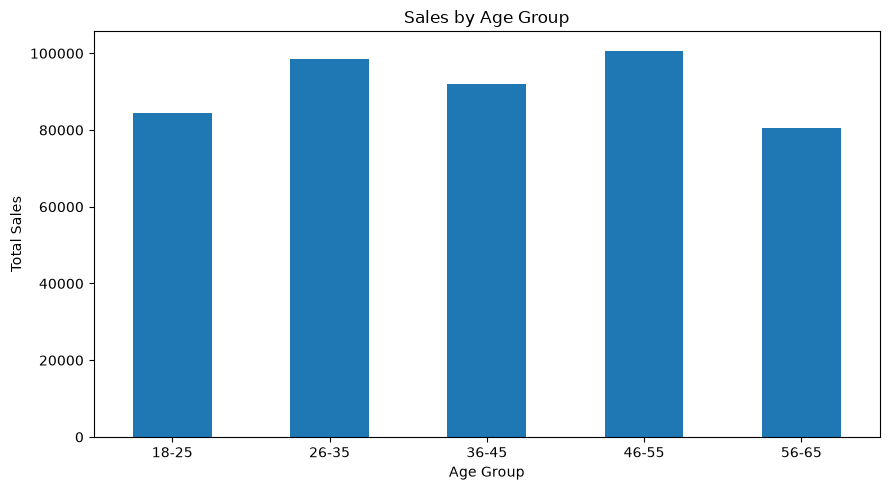

In [17]:
# Age Group Sales Analysis

plt.figure(figsize=(9, 5))

age_group_sales.plot(kind="bar")

plt.title("Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

* The 46-55 age group generated the highest sales of ₹1,00,690.
* The 26-35 age group generated the second-highest sales of ₹98,480.
* The 56-65 age group generated the lowest sales of ₹80,410.
* Sales are distributed across all age groups, indicating that the business serves customers from different age segments.


In [18]:
# Calculate sales by gender

gender_sales = df.groupby("Gender")["Total Amount"].sum()

print("Sales by Gender:")
print(gender_sales)

Sales by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


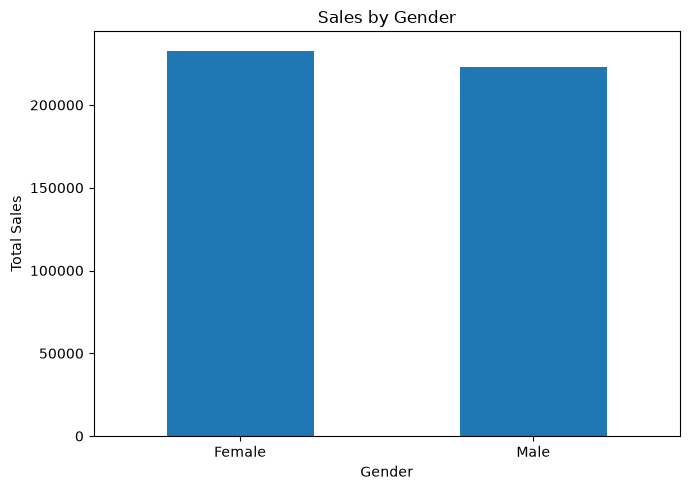

In [19]:
# Gender-wise Sales Analysis

plt.figure(figsize=(7, 5))

gender_sales.plot(kind="bar")

plt.title("Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

* Female customers generated total sales of ₹2,32,840.
* Male customers generated total sales of ₹2,23,160.
* Female customers generated slightly higher sales than male customers.
* The difference between female and male sales is relatively small, indicating fairly balanced sales across genders.


In [20]:
# Calculate revenue by product category

category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

print("Revenue by Product Category:")
print(category_revenue)

Revenue by Product Category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


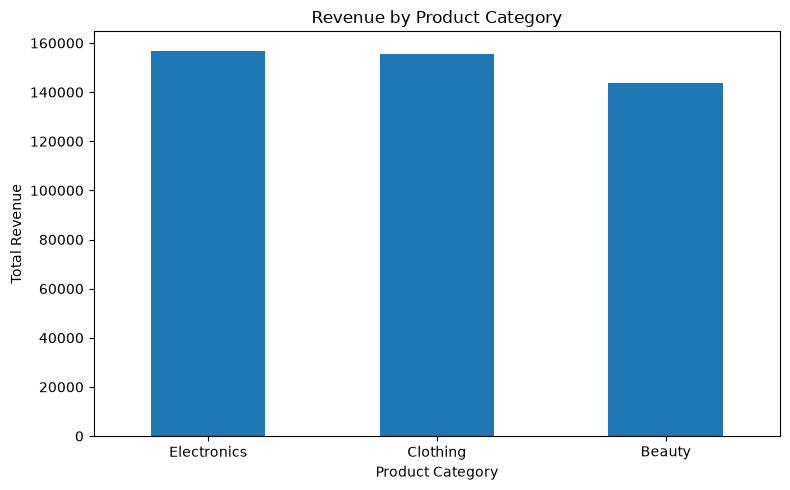

In [21]:
# Product Category Revenue Analysis

plt.figure(figsize=(8, 5))

category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

* Electronics generated the highest revenue of ₹1,56,905.
* Clothing generated ₹1,55,580 in revenue and was the second-highest category.
* Beauty generated the lowest revenue among the three categories, with ₹1,43,515.
* The revenue difference between Electronics and Clothing is small, while Beauty has comparatively lower revenue.


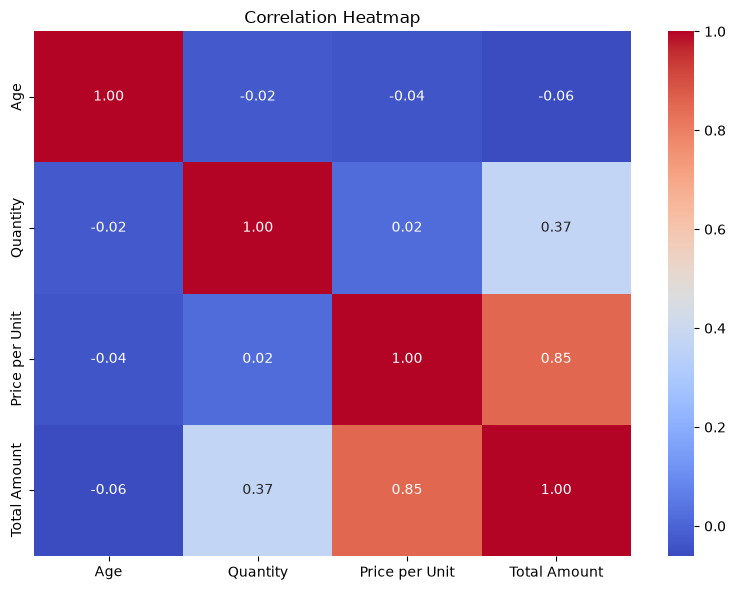

In [22]:
# Correlation Heatmap

correlation = df[[
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

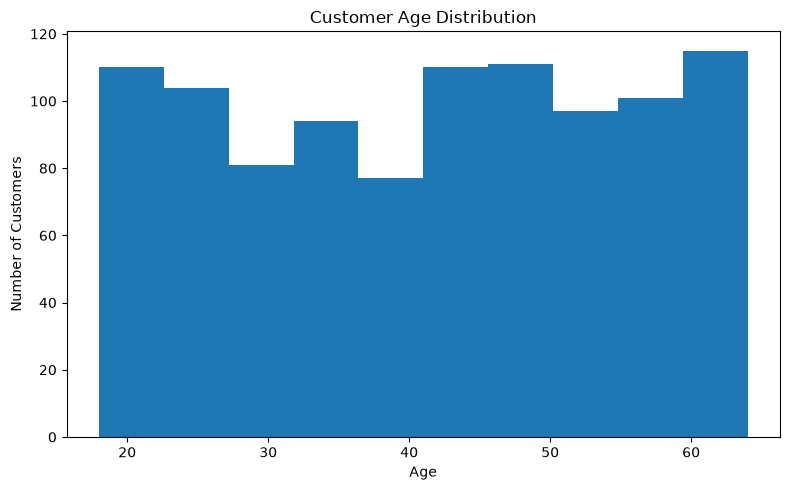

In [23]:
# Age Distribution

plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=10)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Observation

* The age distribution shows that customers belong to a wide range of age groups.
* Most customers are concentrated around the middle-age range.
* The business attracts customers from both younger and older age groups.
* Understanding the age distribution can help the business design better-targeted marketing campaigns.


### Dataset Limitation

* The dataset contains product categories such as Electronics, Clothing, and Beauty, but it does not contain individual product names.
* Therefore, product-level Top 10 analysis could not be performed.
* Instead, revenue by product category was analyzed to identify the best-performing categories.


## Conclusion

The exploratory data analysis of the retail sales dataset provided useful insights into sales trends, customer demographics, and product category performance. Monthly and quarterly analysis showed variations in sales throughout the year, with Q4 2023 recording the highest quarterly sales. The analysis also showed that customers from different age groups contribute to sales, with the 46-55 age group generating the highest sales. Female customers generated slightly higher total sales than male customers. Among product categories, Electronics generated the highest revenue.

## Actionable Business Recommendations

1. **Focus on high-performing categories:**
   The business should maintain sufficient inventory and promotional activities for Electronics and Clothing, as these categories generated the highest revenue.

2. **Target customer segments:**
   Marketing campaigns can focus more on the 26-55 age groups, especially the 46-55 segment, while continuing to serve other age groups.

3. **Plan promotions around sales trends:**
   The business can increase promotional campaigns, offers, and inventory during high-performing periods such as Q4 and identify strategies to improve sales during weaker months.
